<a href="https://colab.research.google.com/github/wpaek/HIDSI_JAX_workshop/blob/main/Oct1JAXworkshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

In [ ]:
def f(x):
    return x**2

df   = jax.grad(f)
d2f  = jax.grad(jax.grad(f))

print(f(3.0), df(3.0), d2f(3.0))

9.0 6.0 2.0


In [ ]:
xs = jnp.linspace(-2*jnp.pi, 2*jnp.pi, 300)

jax.grad(jnp.sin)(1.0)
jax.grad(jnp.sin)(xs)     # fails

TypeError: Gradient only defined for scalar-output functions. Output had shape: (300,). To get the gradient, reduce the output to a scalar with output.sum(), or use jax.jacobian to differentiate a function with a non-scalar output.

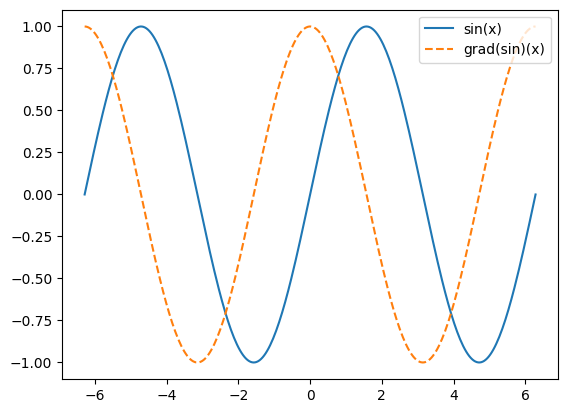

In [ ]:
dsin = jax.vmap(jax.grad(jnp.sin))

plt.plot(xs, jnp.sin(xs), label="sin(x)")
plt.plot(xs, dsin(xs), '--', label="grad(sin)(x)")
plt.legend()

In [ ]:
def slow(x):
    for _ in range(20):
        x = jnp.sin(x) * jnp.cos(x) + 0.5 * x
    return x

fast = jax.jit(slow)
x = jnp.linspace(0, 1, 1_000_000)

fast(x).block_until_ready()          # warm-up compile — don't time this one

%timeit slow(x).block_until_ready()
%timeit fast(x).block_until_ready()

358 ms ± 10.6 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
182 ms ± 49.7 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


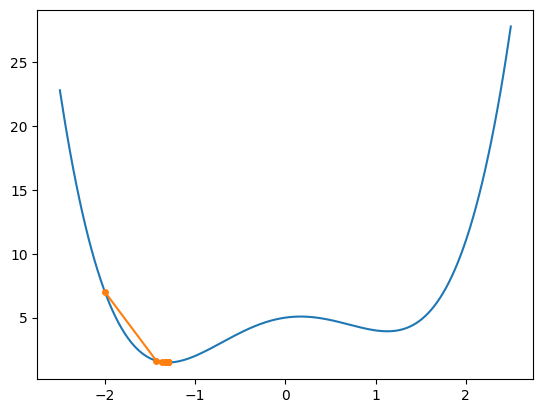

In [ ]:
def loss(x):
    return x**4 - 3*x**2 + x + 5

g = jax.jit(jax.grad(loss))

x = -2.0 #starting point
path = [x]
for _ in range(50):
    x = x - 0.03 * g(x) #step change
    path.append(x)

xs = jnp.linspace(-2.5, 2.5, 300)
plt.plot(xs, loss(xs))
plt.plot(jnp.array(path), loss(jnp.array(path)), 'o-', ms=4)